# EDA Visualization

Sample Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)
n = 120
age = rng.integers(20, 61, n)
income = np.clip(18000 + age * 950 + rng.normal(0, 9000, n), 18000, None).round()
visits = rng.integers(1, 15, n)
monthly_spend = np.clip(300 + income * 0.028 + visits * 105 + rng.normal(0, 650, n), 100, None).round()
department = rng.choice(['Electronics', 'Clothing', 'Grocery'], n, p=[0.35, 0.4, 0.25])
member = rng.choice(['Basic', 'Silver', 'Gold'], n, p=[0.5, 0.3, 0.2])
purchased = np.where((monthly_spend > np.median(monthly_spend)) | (visits > 10), 'Yes', 'No')
df = pd.DataFrame({'Age': age, 'Income': income, 'Visits': visits,
                   'Monthly_Spend': monthly_spend, 'Department': department,
                   'Membership': member, 'Purchased': purchased})
# Dates are used for the time-series line plot.
df['Purchase_Date'] = pd.date_range('2026-01-01', periods=n, freq='D')
print(df.head())
print('Dataset dimensions:', df.shape)

   Age   Income  Visits  Monthly_Spend   Department Membership Purchased  \
0   23  32058.0       4         1192.0      Grocery     Silver        No   
1   51  75165.0      13         2374.0      Grocery     Silver       Yes   
2   46  46554.0       2         1708.0  Electronics     Silver        No   
3   37  50136.0       8         1853.0     Clothing     Silver        No   
4   37  54615.0       7         2220.0  Electronics      Basic        No   

  Purchase_Date  
0    2026-01-01  
1    2026-01-02  
2    2026-01-03  
3    2026-01-04  
4    2026-01-05  
Dataset dimensions: (120, 8)


# 1. Histogram
# Definition
A histogram groups numerical observations into intervals and shows how often values occur. It is useful for understanding the shape of a continuous feature and locating common value ranges. Here, customer age is numerical, so grouping it into age intervals makes sense.

# Business Example
A retail company wants to understand which customer age groups are most common. Age ranges can guide advertising, store layout, and product selection. A histogram is more meaningful than listing every customer age separately. It also helps the team notice whether customers are concentrated in a narrow age range.

# AI/ML Use
In ML, age distribution can reveal imbalance in the input data. It may suggest whether the training set represents younger and older customers fairly. Extreme ages may also need checking before model training. The histogram helps select preprocessing and data collection steps.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

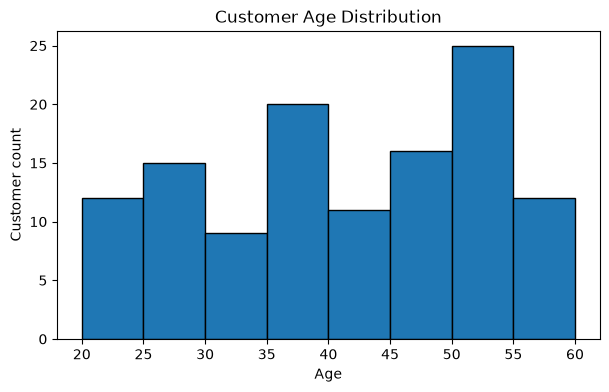

In [2]:
plt.figure(figsize=(7, 4))
plt.hist(df['Age'], bins=8, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Customer count')
plt.title('Customer Age Distribution')
plt.show()

# Explanation and Interpretation
The horizontal axis shows age intervals and the vertical axis shows customer counts. Taller bars indicate age groups with more customers. Look for clusters, gaps, or unusual extremes.

# Insight Obtained
Age values span roughly 20–60 in this generated sample; the histogram shows which intervals contain more customers.

# 2. Box Plot
# Definition
A box plot summarizes a numerical variable using its median, quartiles, and whiskers. Points beyond the whiskers can indicate possible outliers, but are not automatically errors. It is especially useful for comparing spread across groups. Here, spending differs across membership groups, so a grouped box plot is meaningful.

# Business Example
A business compares how much Basic, Silver, and Gold customers spend. A box plot shows the typical spending level and the variation within each group. The team can spot groups with unusually high spenders. It can then investigate whether those customers are valuable or whether the data needs verification.

# AI/ML Use
Box plots help ML teams check for extreme numerical values and differences between categories. Outliers can affect models such as linear regression. Group comparisons can suggest useful predictive features. However, outlier decisions must consider business context.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

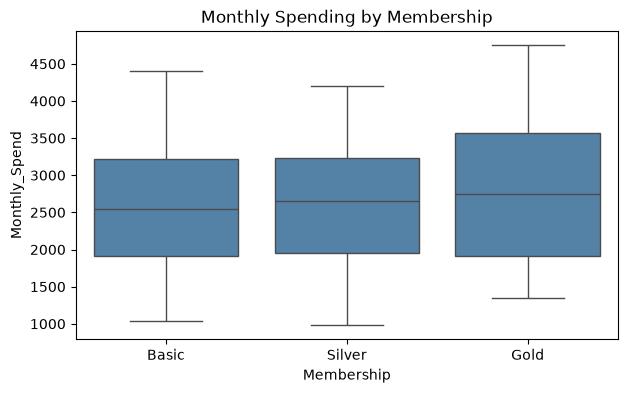

In [3]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Membership', y='Monthly_Spend', order=['Basic', 'Silver', 'Gold'], color='steelblue')
plt.title('Monthly Spending by Membership')
plt.show()

# Explanation and Interpretation
Each box shows the middle half of spending values for one membership group. The line inside each box is the median. Compare medians and box heights to understand differences in typical spending and variation.

# Insight Obtained
Compare the three membership groups to see whether one has higher typical spending or greater variability; the sample is randomly generated, so differences need not be meaningful.

# 3. Bar Chart
# Definition
A bar chart compares a numerical summary across categories. Unlike a count plot, its bar heights can represent sums, averages, or other measurements. Here, total customer spending is grouped by department. This makes it useful for comparing departmental sales contributions.

# Business Example
A store manager wants to compare total spending in Electronics, Clothing, and Grocery. The bars help identify which department contributes more revenue in the sample. This can inform inventory and staffing discussions. However, totals also depend on the number of customers in each department.

# AI/ML Use
In ML analysis, aggregated category summaries can reveal relationships between a category and a numeric feature. They may suggest features such as department-level average spending. Teams should avoid creating aggregates from validation or test data during training. The bar chart is a simple way to inspect group-level differences.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

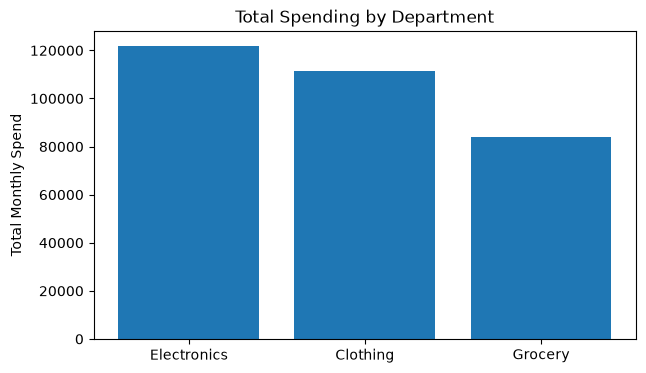

In [4]:
totals = df.groupby('Department')['Monthly_Spend'].sum().sort_values(ascending=False)
plt.figure(figsize=(7, 4))
plt.bar(totals.index, totals.values)
plt.ylabel('Total Monthly Spend')
plt.title('Total Spending by Department')
plt.show()

# Explanation and Interpretation
The height of each bar represents total monthly spending for that department. Higher bars indicate a larger combined spending amount. This chart compares totals, not average customer spending.

# Insight Obtained
The department with the tallest bar has the highest combined spending in the sample; customer counts should be considered when interpreting the result.

# 4. Count Plot
# Definition
A count plot displays how many records belong to each category. It is appropriate for categorical variables when the goal is to compare frequencies. Unlike a bar chart of sales totals, it counts rows directly. Here, purchase status is a categorical target with Yes and No values.

# Business Example
A sales team wants to know how many customers purchased and how many did not. A count plot shows the difference quickly. This helps the team understand conversion outcomes. A large gap can motivate investigation of customer behavior and marketing strategy.

# AI/ML Use
Class balance matters in classification problems. If one target class is rare, accuracy alone can be misleading. A count plot provides an early check before model selection and evaluation. It may motivate stratified splitting or metrics such as precision and recall.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

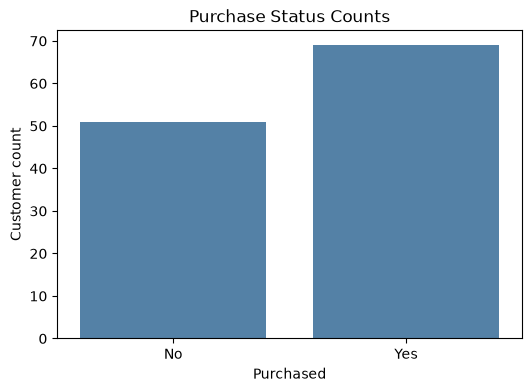

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Purchased', order=['No', 'Yes'], color='steelblue')
plt.title('Purchase Status Counts')
plt.ylabel('Customer count')
plt.show()

# Explanation and Interpretation
Each bar counts the records labeled No or Yes. Compare the two heights to judge whether the target is balanced. A large difference suggests potential class imbalance.

# Insight Obtained
The plot reveals whether the generated purchase labels are evenly distributed; check the actual bar heights before choosing classification metrics.

# 5. Scatter Plot
# Definition
A scatter plot displays two numerical variables as points. It is used to examine direction, strength, and unusual patterns in their relationship. Each point represents one observation. Here, income and spending are numerical, making a scatter plot appropriate.

# Business Example
A retailer wants to know whether higher-income customers tend to spend more. A scatter plot shows each customer’s income and monthly spending together. An upward pattern suggests a positive relationship. The team can also notice customers who spend unusually little or much for their income.

# AI/ML Use
Scatter plots can identify predictive relationships before fitting regression models. They help reveal nonlinearity, clusters, and potential outliers. A visible association does not prove causation. The pattern can guide feature selection and model choice.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

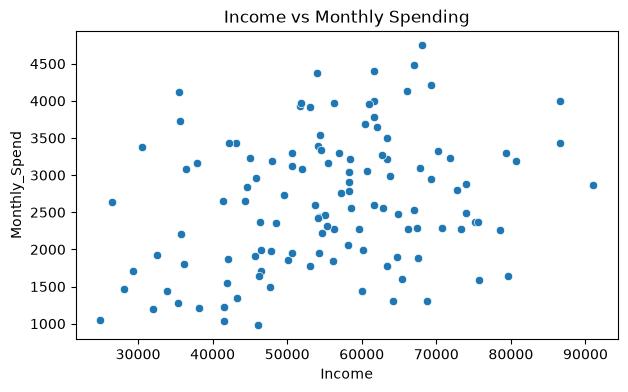

In [6]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='Income', y='Monthly_Spend')
plt.title('Income vs Monthly Spending')
plt.show()

# Explanation and Interpretation
Each dot represents one customer. An overall upward slope suggests higher income is associated with higher spending. Wide scatter around the pattern indicates other factors also matter.

# 6. Line Plot
# Definition
A line plot connects values in a meaningful order, usually time. It is used to observe changes, trends, and fluctuations across dates. Connecting unordered customer categories would be misleading. Here, daily spending totals are arranged chronologically.

# Business Example
A store monitors daily spending over several months. A line chart shows periods with higher and lower spending. It can help staff plan for busy days and investigate unusual changes. Repeated peaks may suggest seasonal demand when enough history is available.

# AI/ML Use
Time-based plots help identify trends, shifts, and possible seasonality before forecasting. They can reveal whether time features are useful. A time-aware train/test split may be needed to avoid leakage. Here, the data is synthetic, so no real seasonal conclusions should be drawn.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

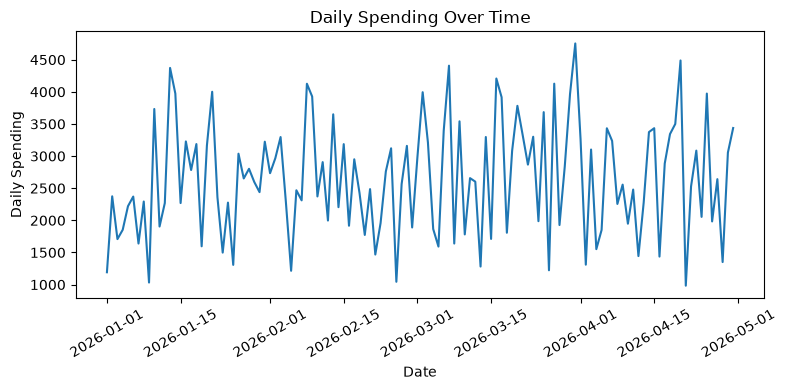

In [7]:
daily = df.groupby('Purchase_Date')['Monthly_Spend'].sum()
plt.figure(figsize=(8, 4))
plt.plot(daily.index, daily.values)
plt.xlabel('Date')
plt.ylabel('Daily Spending')
plt.title('Daily Spending Over Time')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Explanation and Interpretation
The horizontal axis shows dates and the vertical axis shows spending recorded on each date. Peaks represent higher-spending days and dips lower-spending days. The line makes changes over time easy to follow.

# 7. Violin Plot
# Definition
A violin plot shows the distribution of a numerical variable within categories. Its width represents where values are more concentrated. It combines information about shape with a grouped comparison. Here, spending distributions are compared across departments.

# Business Example
A retail manager wants to see whether spending differs across departments. A violin plot shows not only typical spending but also where customers cluster. A wide part of a violin means many values occur around that range. This can help identify varied customer spending behavior.

# AI/ML Use
In ML, violin plots help compare numerical feature distributions across categories or target classes. They can reveal overlap, skewness, or multiple peaks. These patterns can indicate whether a feature is useful for classification. The plot is descriptive and does not establish statistical significance.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

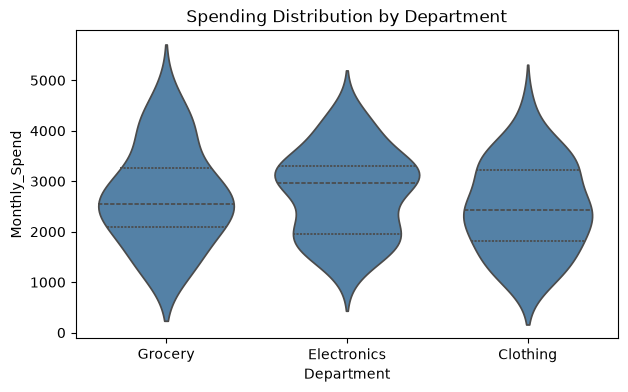

In [8]:
plt.figure(figsize=(7, 4))
sns.violinplot(data=df, x='Department', y='Monthly_Spend', inner='quartile', color='steelblue')
plt.title('Spending Distribution by Department')
plt.show()

# Explanation and Interpretation
The width of each violin indicates where spending values are concentrated. The internal quartile markers help compare central ranges. Compare the shapes to see whether departments differ in spread or concentration.

# 8. Pair Plot
# Definition
A pair plot displays pairwise relationships among several numerical features. Scatter plots appear off the diagonal and one-variable distributions appear on the diagonal. It is helpful for an initial overview of multiple features. We use only a few columns so the graph stays readable.

# Business Example
A business analyst wants to compare customer age, income, visits, and spending together. A pair plot avoids creating many separate scatter plots manually. It helps reveal which variables move together. It also shows whether a feature has unusual values or a distinctive distribution.

# AI/ML Use
Pair plots can reveal redundant features, possible nonlinear relationships, and class separation. They are useful before feature selection and model building. Large datasets may require sampling for speed and readability. Correlation and predictive value should be checked separately.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

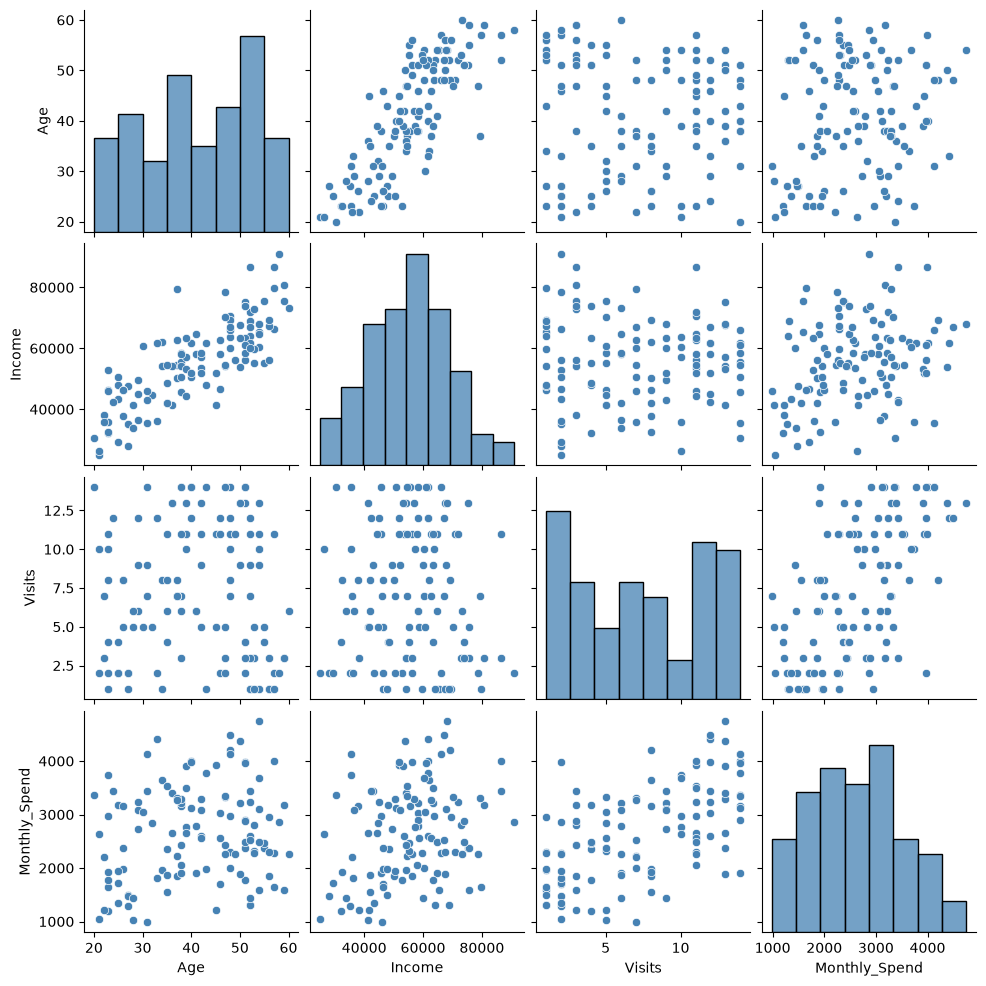

In [9]:
sns.pairplot(df[['Age', 'Income', 'Visits', 'Monthly_Spend']], diag_kind='hist', diag_kws={'color': 'steelblue'}, plot_kws={'color': 'steelblue'})
plt.show()

# Explanation and Interpretation
The diagonal panels show each feature on its own. Other panels show two-feature scatter plots. Look for upward or downward patterns and isolated points.

# 9. Heatmap
# Definition
A heatmap represents values in a matrix using color intensity. For numerical EDA, a correlation heatmap helps compare many pairwise linear relationships. Correlation ranges from -1 to +1, while values near zero indicate weak linear association. A heatmap is useful when several numerical features are available.

# Business Example
A retail analyst wants to understand how age, income, visits, and spending relate. A correlation heatmap provides a compact summary. Strong positive or negative values stand out visually. This helps the analyst decide which pairs deserve closer inspection.

# AI/ML Use
Correlation heatmaps can flag potentially redundant numerical features. Highly correlated predictors may cause multicollinearity problems in some linear models. Correlation alone does not establish causation or target importance. Feature decisions should also consider domain knowledge and validation results.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

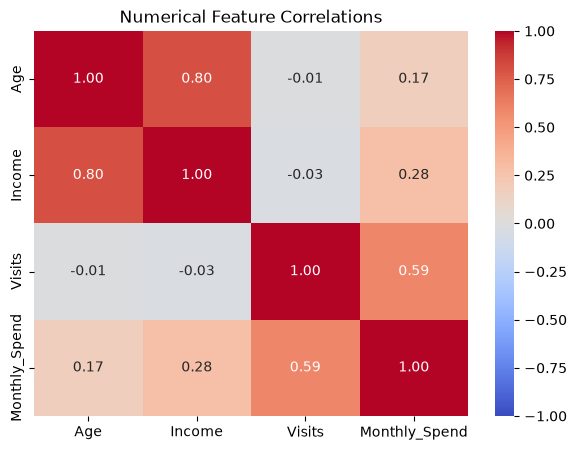

In [10]:
corr = df[['Age', 'Income', 'Visits', 'Monthly_Spend']].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Numerical Feature Correlations')
plt.show()

# Explanation and Interpretation
Each cell contains a correlation coefficient for a pair of features. Values close to +1 indicate strong positive linear relationships; values close to -1 indicate strong negative ones. Values near zero indicate weak linear association.

# 10. Distribution Plot
# Definition
A distribution plot shows the shape of one numerical feature, often combining a histogram with a density curve. It helps compare common values and tail behavior. Here, monthly spending is numerical and may be unevenly distributed. We use a histogram with KDE to examine its overall shape.

# Business Example
A store wants to know whether most customers spend a modest amount or whether spending is spread widely. The plot highlights common spending ranges and possible long tails. This helps define customer segments and promotional strategies. Unusually high values should be reviewed rather than automatically deleted.

# AI/ML Use
Distribution plots help identify skewness, potential outliers, and preprocessing needs. Highly skewed features may benefit from suitable transformations in some models. Scaling decisions also depend on model type. The KDE is a smooth estimate and can be sensitive to sample size.

# Why This Visualization Was Selected
This chart directly matches the variable type and analysis question described above. It is used to answer that question rather than to add a decorative graph.

# Python Example

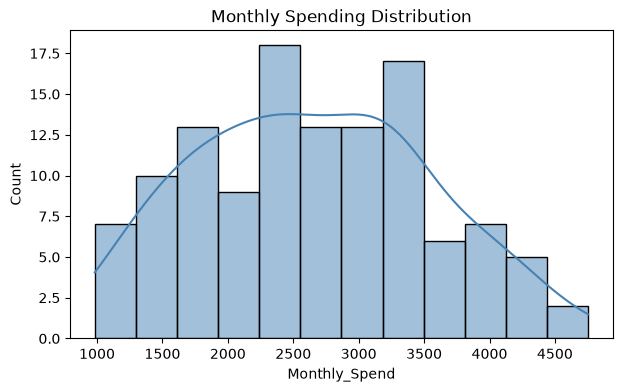

In [11]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='Monthly_Spend', bins=12, kde=True, color='steelblue')
plt.title('Monthly Spending Distribution')
plt.show()

# Explanation and Interpretation
The bars show how many customers fall in each spending interval. The smooth line estimates the density of spending values. Check where the distribution peaks and whether one tail extends farther than the other.